**-Importacion de librerias:**

In [74]:
import numpy as np

import urllib.request, zipfile
from collections import Counter
import tensorflow as tf
from tensorflow.keras import layers

import matplotlib.pyplot as plt
import io

#**Clase Word2Vec:**

In [41]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

In [49]:
class Word2Vec:  #skipgram
  def __init__(self, vocab_size, embedd_dim):

    self.vocab_size = vocab_size
    self.embed_dim = embedd_dim

    self.w1 = []
    self.w2 = []

    #inicializacion de pesos con xavier/glorot initialization
    limit = np.sqrt(6 / (vocab_size + embedd_dim))
    self.w1 = np.random.uniform(-limit, limit, size=(vocab_size, embedd_dim))
    self.w2 = np.zeros((vocab_size, embedd_dim))


  def feed_forward(self, target_word, context_word, negative_skip_grams): #target_word array de indices (m,)

    h = self.w1[target_word]  #Fancy indexing w1[[...]]
    pos_vec = self.w2[context_word]                      # (m, N)
    neg_vec = self.w2[negative_skip_grams]

    # Producto punto fila por fila (batched dot product) entre el embedding
    #del target (h) y el vector de contexto de su palabra positiva real (pos_vec).
    #Resultado: un puntaje (score) de similitud por cada muestra del lote, forma: (m,)
    score_pos = np.sum(h * pos_vec, axis=1)  #producto punto entre los embeddings de target y los vectores de contexto de todas las palabras del vocabulario
    score_neg = np.einsum('mn,mkn->mk', h, neg_vec)

    return score_pos, score_neg, h, pos_vec, neg_vec


  def cross_entropy(self, score_pos, score_neg):
    #Binary Cross-Entropy
    # -log σ(x) = log(1 + e^-x)   |   -log σ(-x) = log(1 + e^x)
    l_pos = np.logaddexp(0, -score_pos) #calcula la perdida con los ejemplos positivos
    l_neg = np.sum(np.logaddexp(0, score_neg), axis=1) #calcula la perdida con los ejemplos negativos
    return np.mean(l_pos + l_neg) #perdida global del lote


  def back_propagation(self, score_pos, score_neg, h, pos_vec, neg_vec):

    m = h.shape[0]  #numero de registros para obtener el gradiente promedio

    d_pos = sigmoid(score_pos) - 1    # (m,)
    d_neg = sigmoid(score_neg)        # (m, k)   m= batch size  k = num ejemplos negativos

    dh = d_pos[:, None] * pos_vec + np.einsum('mk,mkn->mn', d_neg, neg_vec)
    dw2_pos = d_pos[:, None] * h / m                 # (m, N)
    dw2_neg = d_neg[:, :, None] * h[:, None, :] / m  # (m, k, N)
    dh = dh / m
    return dh, dw2_pos, dw2_neg


  def gradiente_descendente(self, target_word, contexto, negativas, dh, dw2_pos, dw2_neg, ln):

        np.add.at(self.w1, target_word, -ln * dh)
        np.add.at(self.w2, contexto, -ln * dw2_pos) #actualiza los vectores de las palabras de contexto reales
        np.add.at(self.w2, negativas, -ln * dw2_neg) #actualizas los vectores de todas las palabras negativas


  def fit(self, target_word, context_word, negative_skip_grams, epocas, ln, batch_size):

      n = len(target_word)
      loss_history = []
      for epoca in range(epocas):
        idx = np.random.permutation(n)
        for ini in range(0, n, batch_size):
          b = idx[ini:ini + batch_size]
          score_pos, score_neg, h, pos_vec, neg_vec  = self.feed_forward(target_word[b], context_word[b], negative_skip_grams[b])
          loss = self.cross_entropy(score_pos, score_neg)
          dh, dw2_pos, dw2_neg = self.back_propagation(score_pos, score_neg, h, pos_vec, neg_vec)
          self.gradiente_descendente(target_word[b], context_word[b], negative_skip_grams[b], dh, dw2_pos, dw2_neg, ln)

          loss_history.append(loss)

        #mostrar progreso
        #if epoca % 10 == 0:
        print(f"Epoch {epoca}: Loss = {loss:.4f}")


      return loss_history  #devuelve el historial de la perdida durante las epocas del entrenamiento


  def get_embeddings(self):
    return self.w1



#**Procesamiento de datos:**

**Descargar los datos:**

In [54]:
# DATASET: text8 (Matt Mahoney's Wikipedia Dump)
# - Contiene 100 millones de caracteres de texto plano en inglés (extracto de Wikipedia).
# - Preprocesamiento integrado: Todo en minúsculas, solo letras de la 'a' a la 'z' y espacios.
# - Sin signos de puntuación, sin números y sin caracteres especiales.

urllib.request.urlretrieve("http://mattmahoney.net/dc/text8.zip", "text8.zip") #descargar y guardar el archivo
with zipfile.ZipFile("text8.zip") as z:
    texto = z.read("text8").decode("utf-8")

print(len(texto))
print(texto[:100])
tokens = texto.split() #tokens = palabras
print(len(tokens))
print(tokens[:10])

100000000
 anarchism originated as a term of abuse first used against early working class radicals including t
17005207
['anarchism', 'originated', 'as', 'a', 'term', 'of', 'abuse', 'first', 'used', 'against']


**Crear Vocabulario:**

In [111]:
tokens = tokens[:10000000]
#max_vocab = 40000
min_count = 15 #minimo de veces que tiene que aparecer una palabras
conteo = Counter(tokens) #cuenta cuantas veces aparece cada palabra en toda la lista de tokens

vocab = {"<UNK>": 0} #nicializa el diccionario del vocabulario reservando el indice 0 para un token especial llamado <UNK> (abreviatura de Unknown o desconocido).
for word, c in conteo.most_common():          #ya se ocupo un espacio con <UNK> (max_vocab - 1 (es decir 4,999))
    if c < min_count:  #al llegar a una palabra poco frecuente se corta
      break
    vocab[word] = len(vocab) #agrega la palabra al diccionario con el indice

vocab_size = len(vocab)
print(vocab_size)
print(list(vocab.items())[:10])

27777
[('<UNK>', 0), ('the', 1), ('of', 2), ('and', 3), ('one', 4), ('in', 5), ('a', 6), ('to', 7), ('zero', 8), ('nine', 9)]


In [82]:
print(conteo.most_common(10))

[('the', 629945), ('of', 351170), ('and', 245346), ('one', 228371), ('in', 217121), ('a', 194785), ('to', 187814), ('zero', 149277), ('nine', 135545), ('is', 112896)]


**Vocabulario Inverso:**

In [83]:
inverse_vocab = {index: token for token, index in vocab.items()}
print(list(inverse_vocab.items())[:10])

[(0, '<UNK>'), (1, 'the'), (2, 'of'), (3, 'and'), (4, 'one'), (5, 'in'), (6, 'a'), (7, 'to'), (8, 'zero'), (9, 'nine')]


**Vectorizar el texto original (expresarlo en sus indices):**

In [84]:
vectorize_tokens = [vocab.get(word , 0) for word in tokens] #busca word en el diccionario y devuelve su indice. Si la palabra no existe devuelve 0
print(vectorize_tokens[:10])

[4862, 3071, 12, 6, 183, 2, 2914, 48, 58, 163]


In [85]:
corpus = np.array(vectorize_tokens)
len(corpus)

10000000

In [86]:
print(f"Porcentaje <UNK>: {round(np.mean(corpus == 0)*100,2)} %")

Porcentaje <UNK>: 4.19 %


**Generrar los Skip-Grams:**

-Ejemplos positivos:

In [88]:
#pares positivos (centro, contexto)
window_size = 2
positive_skip_grams, _ = tf.keras.preprocessing.sequence.skipgrams(
      vectorize_tokens,
      vocabulary_size=vocab_size,
      window_size=window_size,
      negative_samples=0,
      seed=42)

positive_skip_grams = np.array(positive_skip_grams)
positive_skip_grams.shape

(36855552, 2)

In [89]:
for target, context in positive_skip_grams[:5]:
  print(f"({target}, {context}): ({inverse_vocab[target]}, {inverse_vocab[context]})")

(3163, 2): (reverse, of)
(1820, 391): (bad, person)
(204, 5): (computer, in)
(17, 265): (by, central)
(2, 853): (of, blood)


.Ejemplos Negativos:

In [90]:
pares = np.array(positive_skip_grams, dtype=np.int32) #convertir a array de numpy
centro = pares[:, 0]  #obtener las palabras centrales
contexto = pares[:, 1]  #obtener las palabras de contexto

#distribucion de muestreo para negativos (frecuencia^0.75) (Distribución Unigrama Suavizada)
tf.random.set_seed(42)
num_ns = 4 #4 muestras negativas por cada positiva

#cuenta cuantas veces aparece cada indice en el corpus
freq = np.bincount(corpus, minlength=vocab_size).astype(np.float32)

freq[0] = 0     #excluir <UNK> poniendo en 0 su frecuencia para que no sea elegida como negativa  ->prob de muestro = 0
p = freq ** 0.75 #probabilidad de muestreo
p = p / p.sum() #probabilidades entre 0 y 1


#conversión de probabilidades a Logits para el Muestreo Negativo (TF)
# - tf.random.categorical espera logaritmos de probabilidades (logits),
#   no probabilidades puras. Por eso se aplica tf.math.log.
# - Nota sobre <UNK>: Como freq[0] = 0, log(0) se vuelve -inf, lo que
#   equivale a una probabilidad de selección cero absoluta para el token <UNK>.
# - [None, :] convierte el vector plano de tamaño (V,) en una matriz de
#   forma (1, V), que es el formato de lote (batch) que exige la función.

logits = tf.math.log(tf.constant(p))[None, :]  # (1, V)

def muestrear_negativas(contexto_batch, num_ns=4):
    m = len(contexto_batch)
    neg = tf.random.categorical(logits, num_samples = m * num_ns)  #saca m * 4 palabras al azar según p, las reorganiza en una matriz (m, 4) (4 negativas por par)
    neg = tf.reshape(neg, (m, num_ns)).numpy()  #reorganiza en una matriz bidimensional de tamaño (m, num_ns)

    #evitar que una negativa coincida con el contexto real
    choque = neg == contexto_batch[:, None]  #compara cada negativa con el contexto real de su fila

    #mientras haya choques, saca tantas palabras nuevas como choques hubo, las pone en esas posiciones y vuelve a comprobar. Cuando no queda ninguno, devuelve neg
    while choque.any():
        nuevos = tf.random.categorical(logits, num_samples=int(choque.sum())).numpy()[0]
        neg[choque] = nuevos
        choque = neg == contexto_batch[:, None]
    return neg

#generar todas las negativas por bloques
#reserva una matriz (n, 4) vacía donde se guardarán las negativas de todos los
negative_skip_grams = np.empty((len(centro), num_ns), dtype=np.int32)

#recorre los pares en bloques de 100 mil, llama a muestrear_negativas con los contextos de ese bloque y guarda el resultado en las filas correspondientes
paso = 100000
for ini in range(0, len(centro), paso):
    fin = ini + paso
    negative_skip_grams[ini:fin] = muestrear_negativas(contexto[ini:fin], num_ns)

In [91]:
print(negative_skip_grams[:5])
negative_skip_grams.shape

[[  425 10065   253 17193]
 [ 9426  1566     8  3056]
 [   10    10 10745 12298]
 [  295  9462 10004  2913]
 [ 1682 20918  7458  1411]]


(36855552, 4)

In [96]:
for i in range(5):
    target = centro[i]
    contexto_positivo = contexto[i]
    negativos = negative_skip_grams[i]

    print(f"Target: {inverse_vocab[target]}")
    print(f"Contexto positivo: {inverse_vocab[contexto_positivo]}")
    print(f"Contextos negativos: {[inverse_vocab[n] for n in negativos]}")
    print("-" * 65)

Target: reverse
Contexto positivo: of
Contextos negativos: ['upon', 'rhodes', 'members', 'doe']
-----------------------------------------------------------------
Target: bad
Contexto positivo: person
Contextos negativos: ['delete', 'arms', 'zero', 'representing']
-----------------------------------------------------------------
Target: computer
Contexto positivo: in
Contextos negativos: ['is', 'is', 'negligible', 'rotated']
-----------------------------------------------------------------
Target: by
Contexto positivo: central
Contextos negativos: ['st', 'acm', 'clowns', 'illegal']
-----------------------------------------------------------------
Target: of
Contexto positivo: blood
Contextos negativos: ['super', 'ramps', 'luxembourg', 'fully']
-----------------------------------------------------------------


#**Entrenar el Word2Vec:**

In [97]:
model = Word2Vec(vocab_size=vocab_size, embedd_dim=128)

historial = model.fit(centro, contexto, negative_skip_grams,
                      epocas=8, ln=10, batch_size=1024)

Epoch 0: Loss = 2.0253
Epoch 1: Loss = 2.0122
Epoch 2: Loss = 1.9505
Epoch 3: Loss = 1.8796
Epoch 4: Loss = 1.9242
Epoch 5: Loss = 1.8917
Epoch 6: Loss = 1.9356
Epoch 7: Loss = 1.8537


**-Visualizar evolucion de la perdida:**

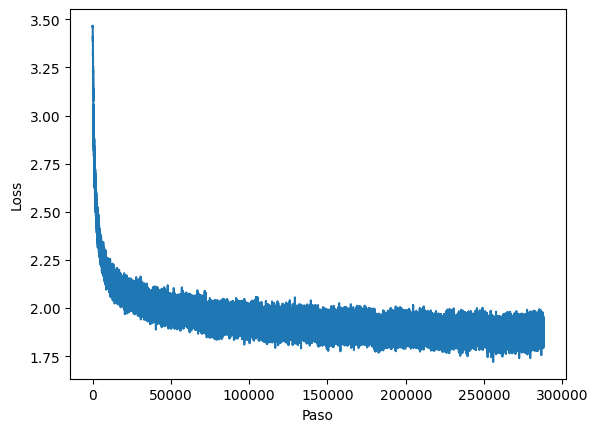

In [98]:
plt.plot(historial)
plt.xlabel("Paso")
plt.ylabel("Loss")
plt.show()

**-Ver los vecinos mas cercanos de una palabra determinada:**

In [110]:
def vecinos(palabra, model, k=5):
    E = model.get_embeddings()
    E = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9) #normalizacion de vectores -> vectores de longitud 1
    sim = E @ E[vocab[palabra]]   #producto punto con la palabra consultada
    mejores = np.argsort(-sim)[1:k+1] #indices de mayor a menor similitud (selecciona a partir del indicie 1 hasta k+1 (para k=5) porque el indice 0 es la misma palabra)
    #mejores = np.argsort(-sim)[0:k]
    return [(inverse_vocab[i], round(float(sim[i]), 3)) for i in mejores]

print(vecinos("king", model))
print(vecinos("one", model))

[('tsar', 0.638), ('emperor', 0.635), ('cleopatra', 0.633), ('prince', 0.63), ('kazimierz', 0.627)]
[('gtb', 0.772), ('nine', 0.752), ('poz', 0.747), ('cyg', 0.742), ('cet', 0.735)]


In [100]:
for w in ["king", "one", "france", "water", "january"]:
    print(w, "->", vecinos(w, model))

king -> [('tsar', 0.638), ('emperor', 0.635), ('cleopatra', 0.633), ('prince', 0.63), ('kazimierz', 0.627)]
one -> [('gtb', 0.772), ('nine', 0.752), ('poz', 0.747), ('cyg', 0.742), ('cet', 0.735)]
france -> [('spain', 0.741), ('belgium', 0.726), ('hungary', 0.716), ('germany', 0.708), ('galicia', 0.682)]
water -> [('sediment', 0.662), ('brackish', 0.633), ('oxygen', 0.622), ('moisture', 0.618), ('salt', 0.618)]
january -> [('november', 0.897), ('june', 0.89), ('september', 0.882), ('july', 0.872), ('october', 0.868)]


**-Guardar los embeddings:**

In [101]:
embeddings = model.get_embeddings()

with io.open("vectors.tsv", "w", encoding="utf-8") as f_vec, \
     io.open("metadata.tsv", "w", encoding="utf-8") as f_meta:
    for i in range(vocab_size):              # incluye <UNK> (indice 0)
        f_vec.write("\t".join(str(x) for x in embeddings[i]) + "\n")
        f_meta.write(inverse_vocab[i] + "\n")

In [102]:
from google.colab import files
files.download("vectors.tsv")
files.download("metadata.tsv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>